# Perbandingan Prediksi dan Harga Aktual: LightGBM (GA) vs XGBoost (GA)

Prediksi dibuat dari lima titik prediksi yang digeser tiap minggu: **3, 10, 17, 24, dan 31 Agustus 2026**. Dari setiap titik, harga diprediksi untuk 1 hari, 1 minggu, dan 30 hari ke depan, lalu dibandingkan dengan harga aktual pada tanggal tersebut.

Pada setiap grafik, sumbu-x berisi komoditas dan nilai MAPE masing-masing model ditulis di bawah nama komoditasnya.

Model yang dipakai adalah model final hasil tuning GA yang dimuat dari disk, **tanpa pelatihan ulang**. Seperti di `predict.ipynb`, yang berubah hanya data riwayat (`last_window`) yang dipotong sampai tanggal titik prediksi.

In [11]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skforecast.utils import load_forecaster

warnings.filterwarnings("ignore")

MODEL_DIRS = {"LightGBM (GA)": "final_lgbm", "XGBoost (GA)": "final_xgb"}
HORIZONS = [1, 7, 30]
ORIGINS = pd.to_datetime(
    ["2026-08-03", "2026-08-10", "2026-08-17", "2026-08-24", "2026-08-31"]
)

## Memuat Model dan Membuat Prediksi

Riwayat harga dalam skala log disusun dari `last_window_` bawaan model (berakhir 3 Agustus) ditambah `log1p` data aktual. Untuk setiap titik prediksi, riwayat dipotong sampai tanggal tersebut, lalu `predict` dipanggil.

In [12]:
df_aktual = pd.read_csv(
    "data_aktual_cleaned.csv", index_col="tanggal", parse_dates=True
).asfreq("D")

forecasters = {
    (model, col, h): load_forecaster(
        str(Path(folder) / f"{folder}_{col}_h{h}.joblib"), verbose=False
    )
    for model, folder in MODEL_DIRS.items()
    for col in df_aktual.columns
    for h in HORIZONS
}

rows = []
for (model, col, h), forecaster in forecasters.items():
    y_log = pd.concat(
        [forecaster.last_window_.iloc[:, 0], np.log1p(df_aktual[col])]
    ).asfreq("D")
    assert not y_log.isna().any(), f"riwayat bolong: {model} {col} h{h}"
    for origin in ORIGINS:
        pred = np.expm1(forecaster.predict(steps=h, last_window=y_log.loc[:origin]))
        rows.extend(
            {
                "Model": model,
                "Komoditas": col,
                "Horizon": h,
                "Titik prediksi": origin,
                "Tanggal": tanggal,
                "Harga Aktual": df_aktual.at[tanggal, col],
                "Harga Prediksi": harga,
            }
            for tanggal, harga in pred.items()
        )

df_pred = pd.DataFrame(rows)
print(len(forecasters), "model,", len(df_pred), "baris prediksi")

54 model, 3420 baris prediksi


## Fungsi Grafik

In [13]:
GAYA = {
    "LightGBM (GA)": {"color": "tab:green", "lw": 3.2, "marker": "o", "ms": 7},
    "XGBoost (GA)": {"color": "tab:orange", "lw": 3.2, "marker": "o", "ms": 7},
}
SINGKATAN = {"LightGBM (GA)": "LGBM", "XGBoost (GA)": "XGB"}
LAMA_PREDIKSI = {1: "1 Hari", 7: "1 Minggu", 30: "30 Hari"}
BULAN = [
    "Januari",
    "Februari",
    "Maret",
    "April",
    "Mei",
    "Juni",
    "Juli",
    "Agustus",
    "September",
    "Oktober",
    "November",
    "Desember",
]


def tgl(t: pd.Timestamp, tahun: bool = False) -> str:
    """Tanggal dalam bahasa Indonesia, mis. '24 Agustus' / '31 Agustus 2026'."""
    return f"{t.day} {BULAN[t.month - 1]}" + (f" {t.year}" if tahun else "")


def plot_hari_terakhir(
    komoditas: list[str], grup: str, xlabel: str, origin: pd.Timestamp, h: int
) -> None:
    """Prediksi vs aktual di hari terakhir horizon H+h dari `origin`; sumbu-x = komoditas."""
    tanggal = origin + pd.Timedelta(days=h)
    d = df_pred[
        (df_pred["Titik prediksi"] == origin)
        & (df_pred["Horizon"] == h)
        & (df_pred["Tanggal"] == tanggal)
        & df_pred["Komoditas"].isin(komoditas)
    ]
    assert len(d) == len(komoditas) * len(MODEL_DIRS), "data prediksi tidak lengkap"
    aktual = d.drop_duplicates("Komoditas").set_index("Komoditas").loc[komoditas]
    per_model = {
        model: dm.set_index("Komoditas").loc[komoditas]
        for model, dm in d.groupby("Model", sort=False)
    }
    # Error per komoditas (1 hari -> MAPE = |prediksi - aktual| / aktual), ditulis
    # di bawah nama komoditas supaya tidak menimpa garis.
    ape = {
        model: (dm["Harga Prediksi"] / dm["Harga Aktual"] - 1).abs() * 100
        for model, dm in per_model.items()
    }
    label = [
        k.removeprefix("Beras Kualitas ")
        + "".join(f"\n{SINGKATAN[m]} {ape[m][k]:.2f}%" for m in per_model)
        for k in komoditas
    ]

    _, ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
    ax.plot(
        label,
        aktual["Harga Aktual"],
        color="black",
        lw=6,
        alpha=0.25,
        marker="s",
        ms=9,
        label="Aktual",
    )
    for model, dm in per_model.items():
        ax.plot(
            label,
            dm["Harga Prediksi"],
            label=f"{model} — MAPE {ape[model].mean():.2f}%",
            **GAYA[model],
        )
    ax.set_title(
        f"{grup}: Prediksi {LAMA_PREDIKSI[h]} dari Titik {tgl(origin)} "
        f"untuk {tgl(tanggal, tahun=True)} (Prediksi vs Aktual)"
    )
    ax.set_xlabel(xlabel)
    ax.margins(x=0.1)  # label komoditas di ujung kiri/kanan tidak terpotong
    ax.set_ylabel("Harga (ribu Rp/kg)")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

## Beras: Prediksi 1 Hari, 1 Minggu, dan 30 Hari dari Setiap Titik Prediksi

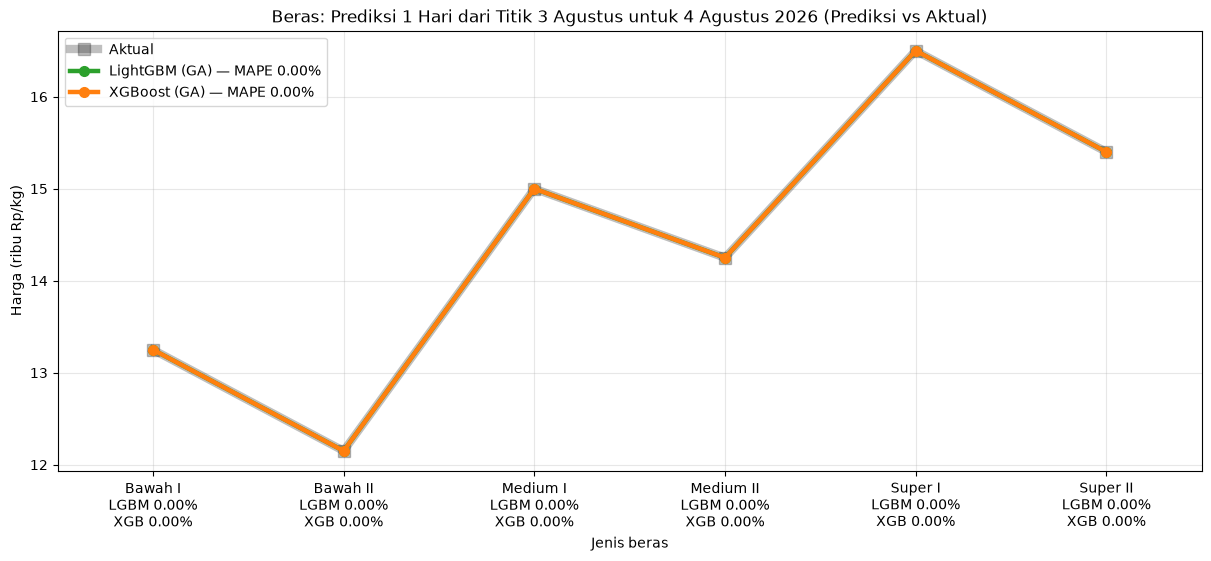

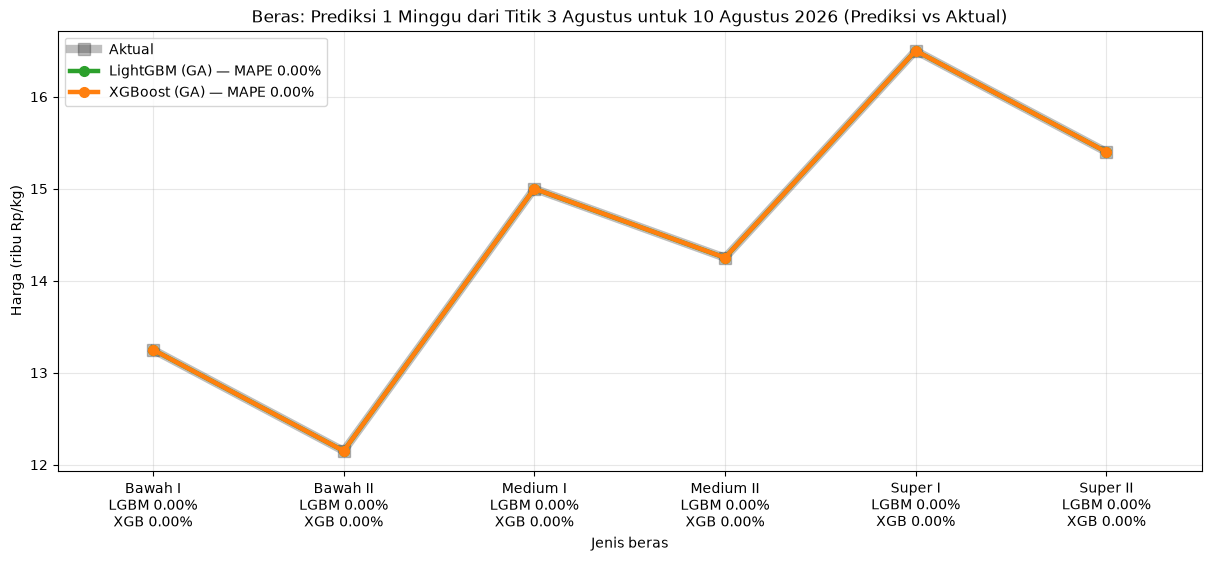

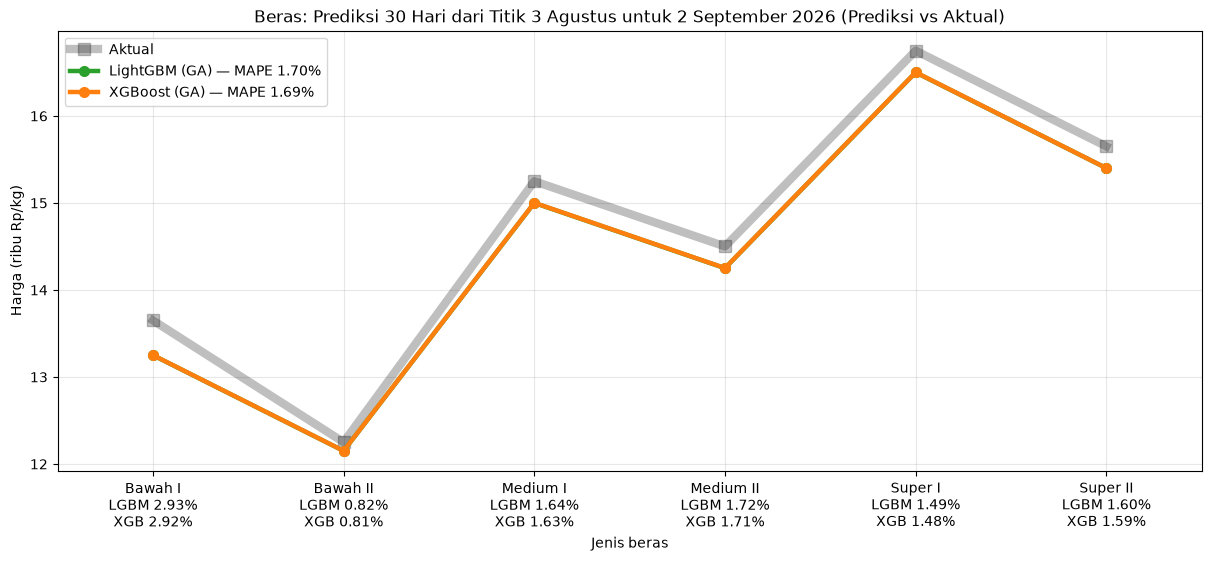

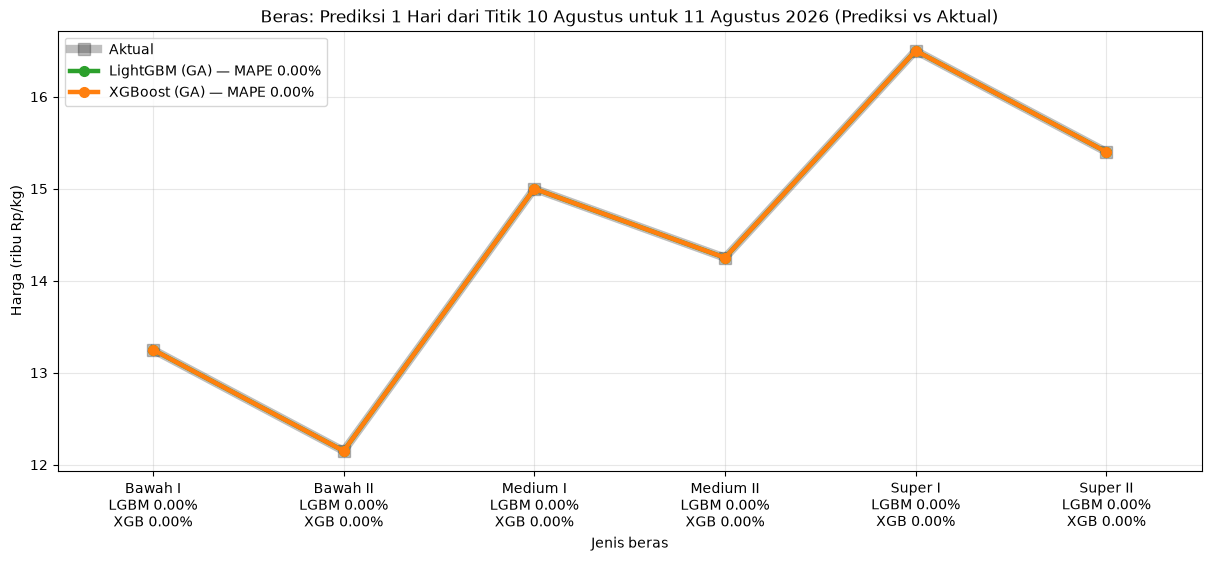

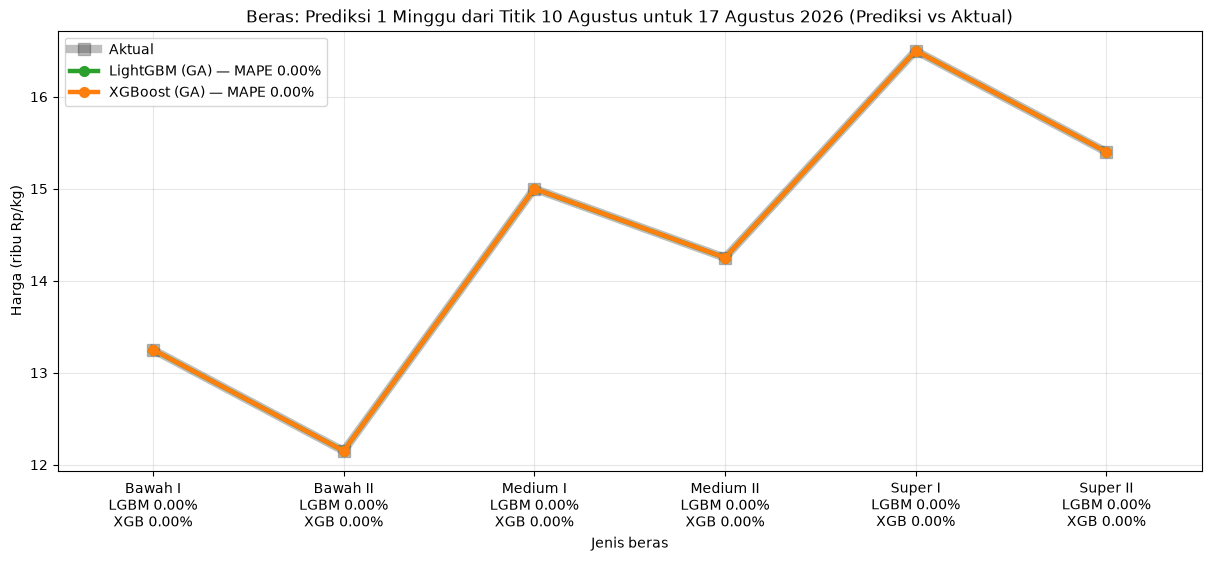

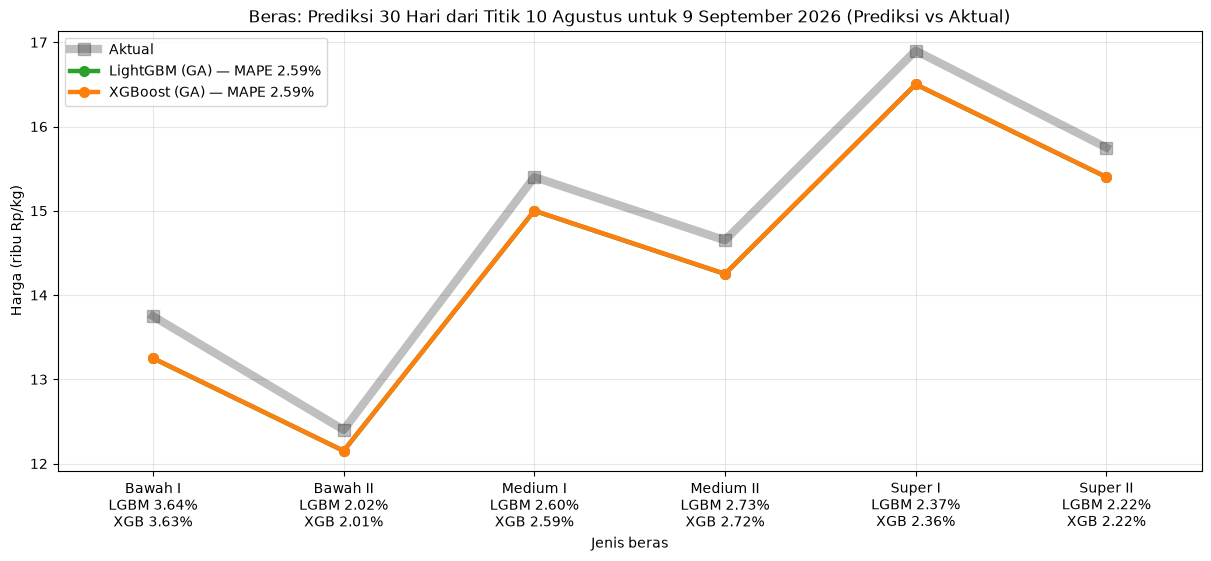

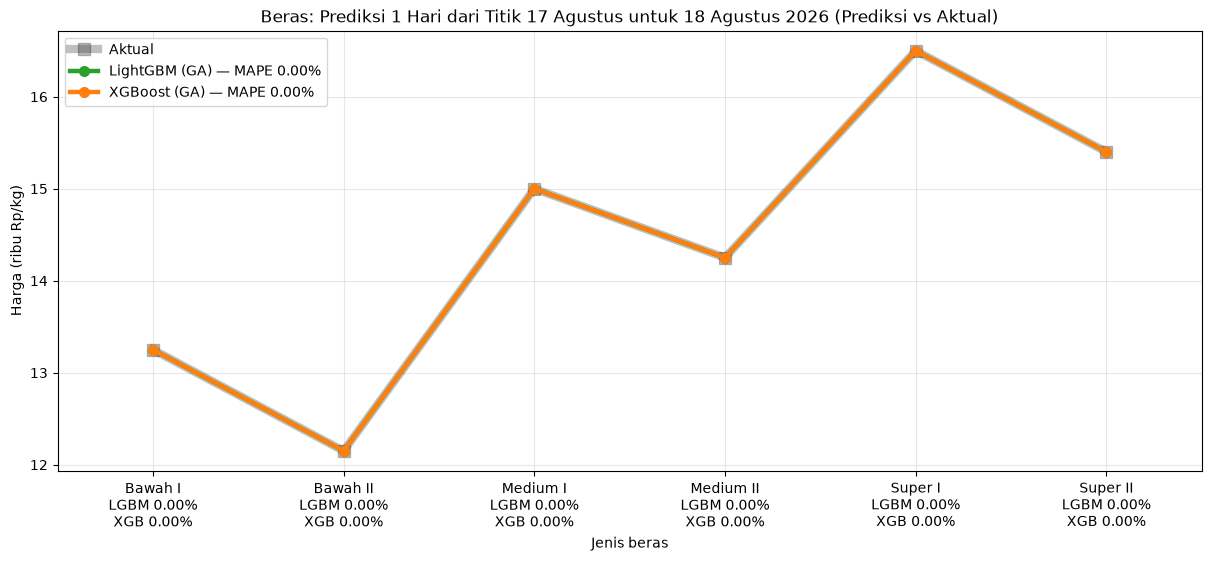

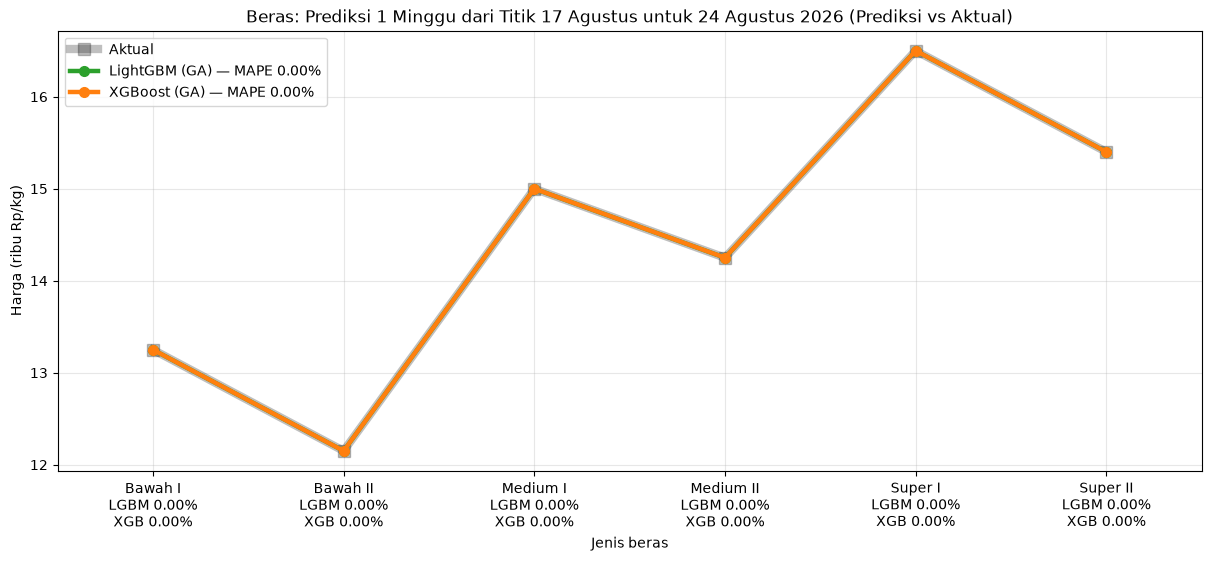

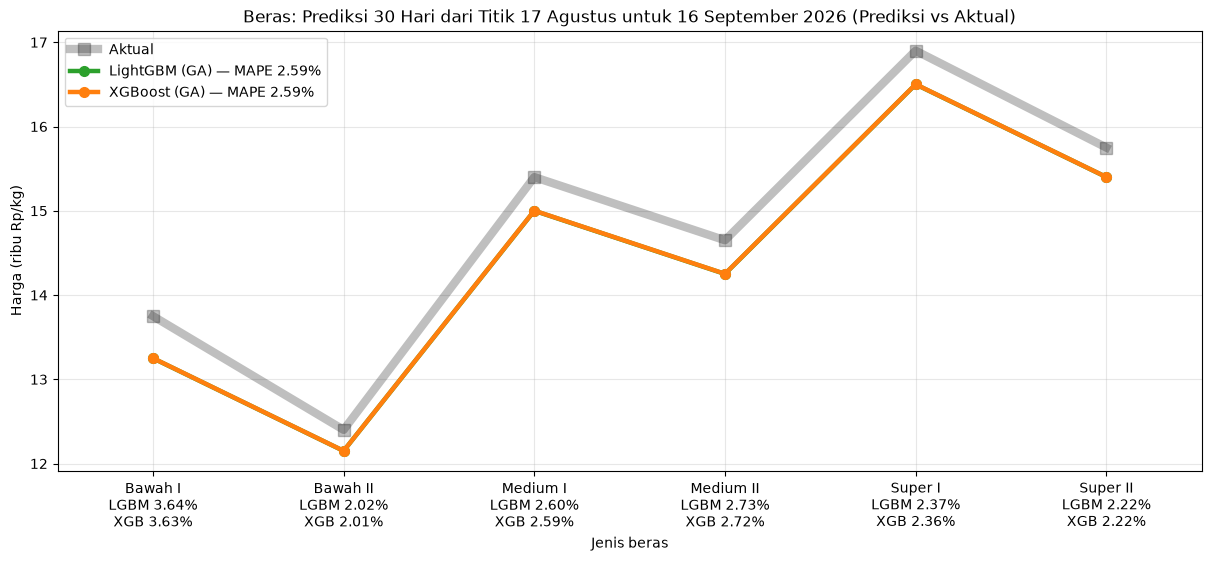

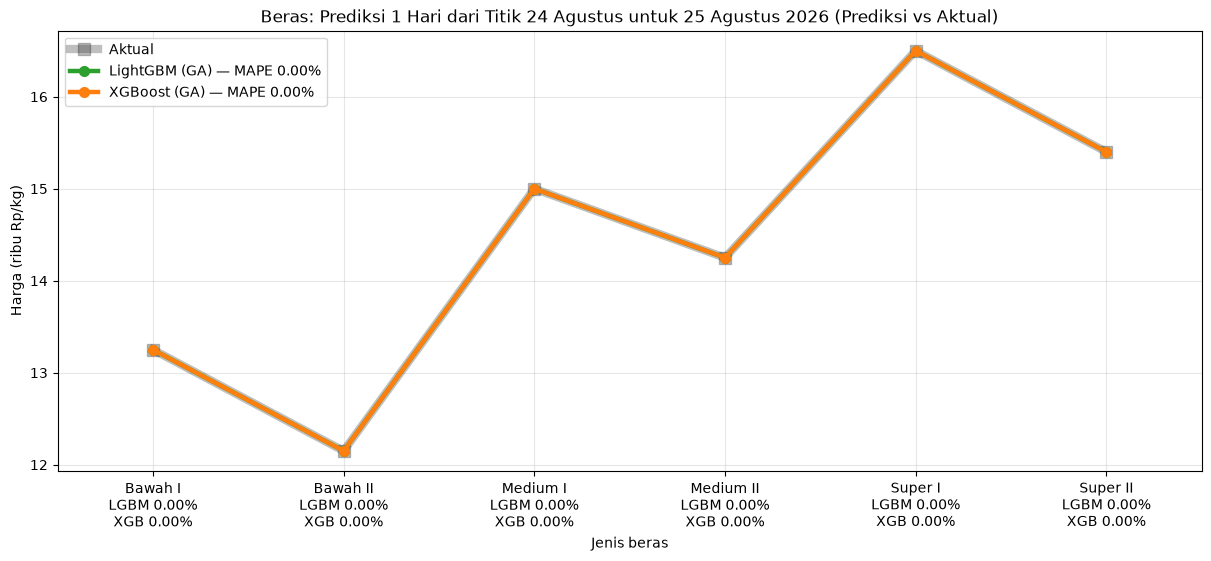

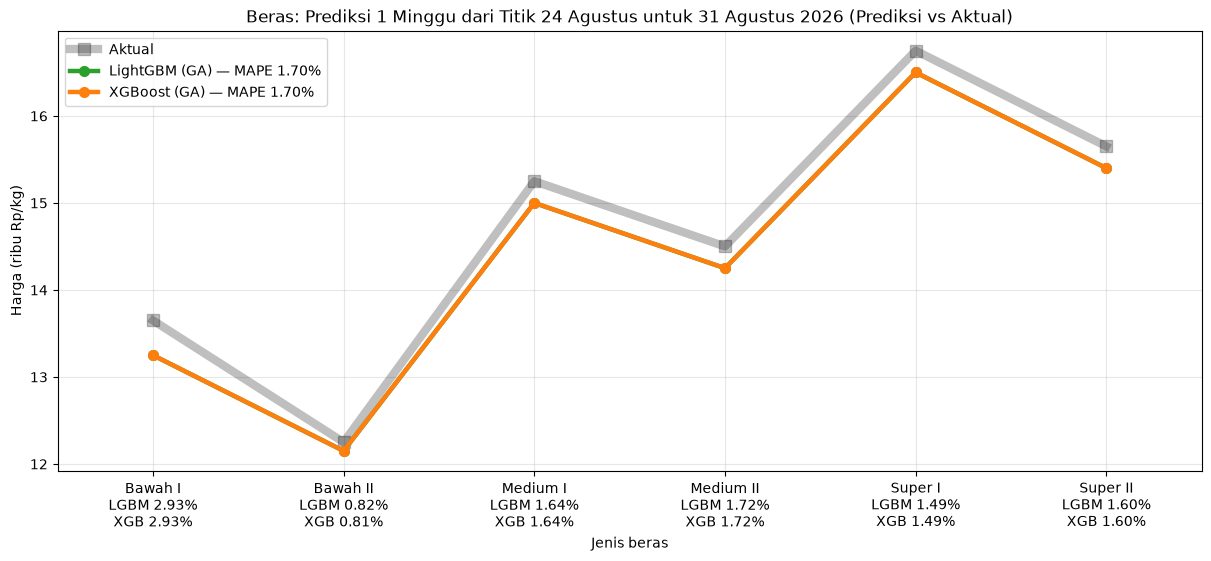

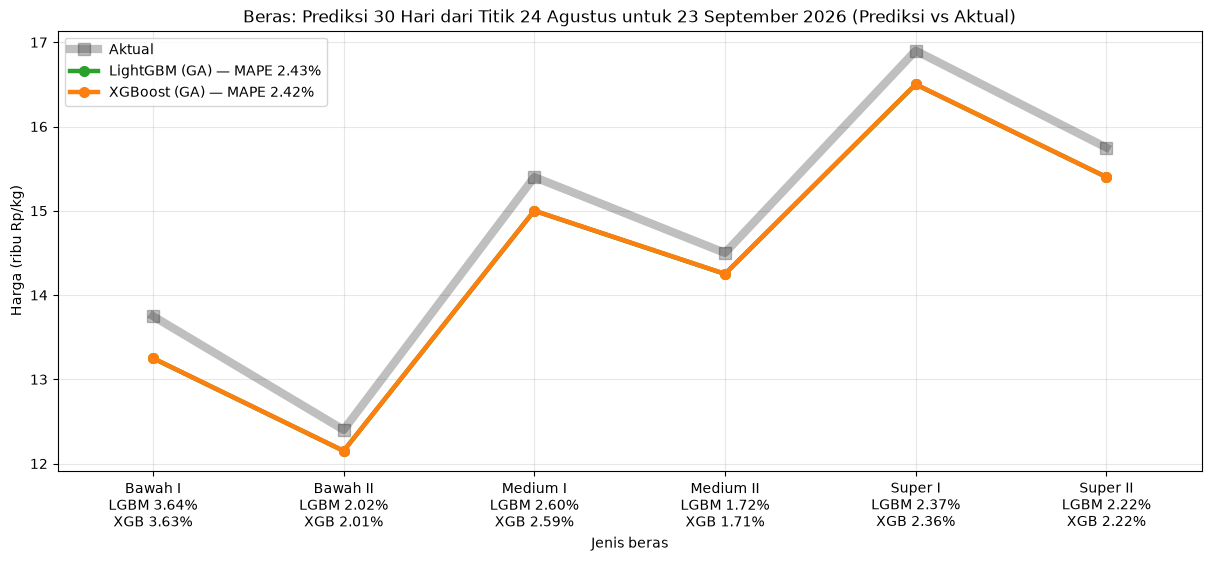

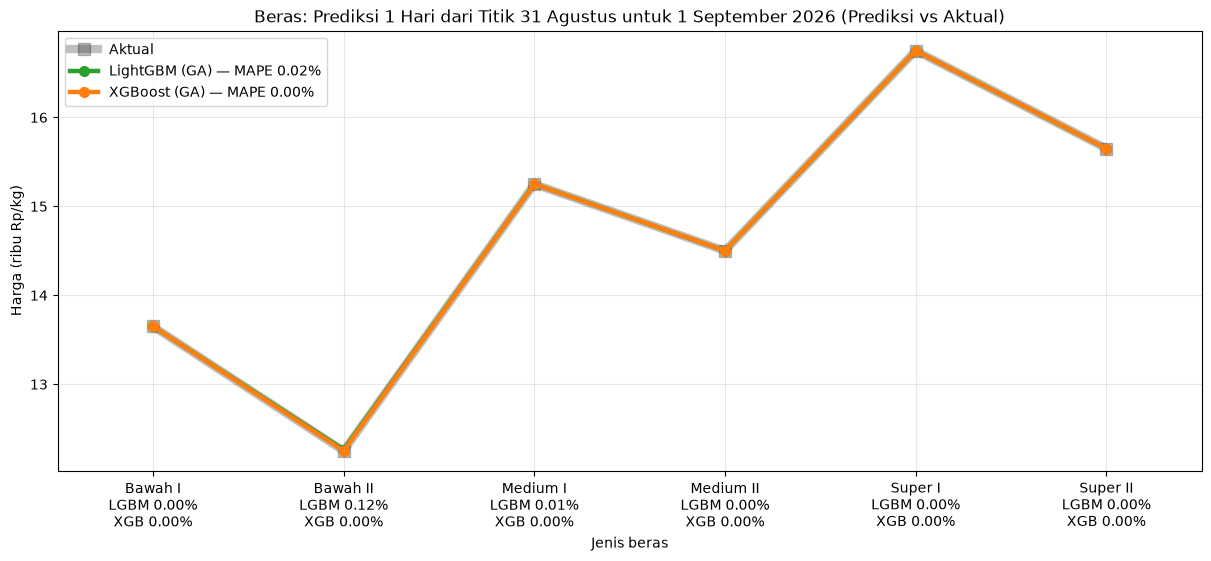

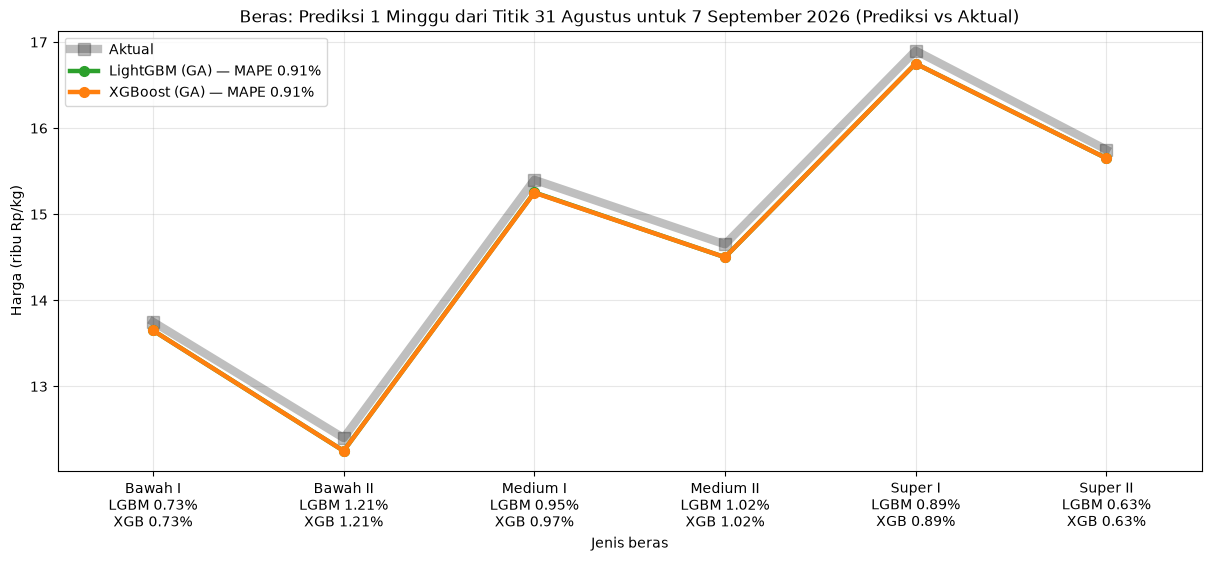

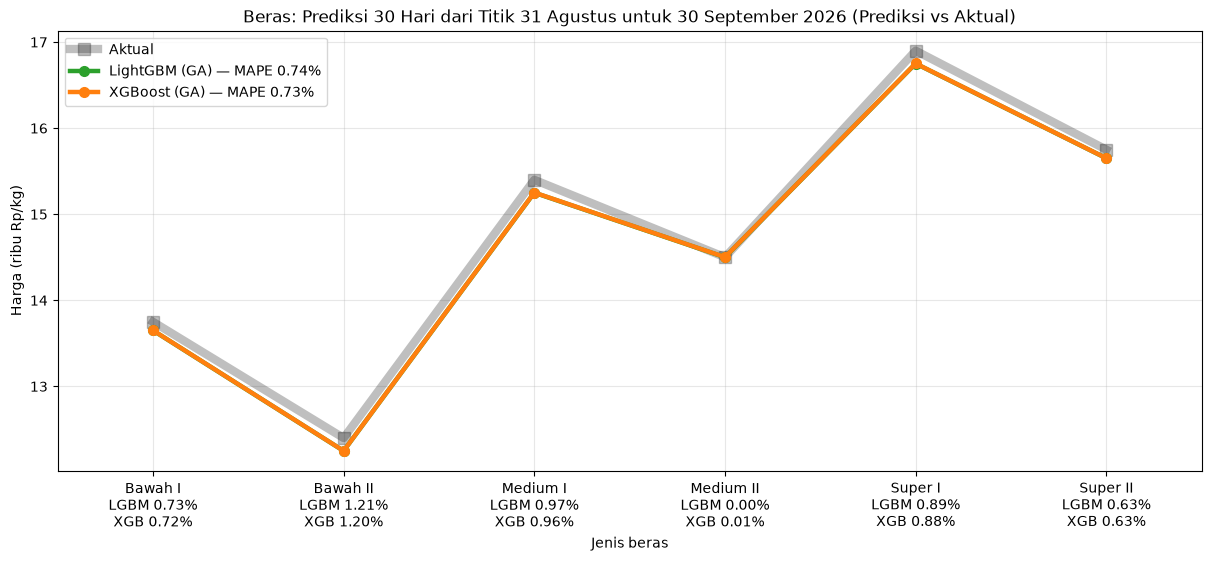

In [14]:
beras = [k for k in df_aktual.columns if k.startswith("Beras")]
for origin in ORIGINS:
    for h in HORIZONS:
        plot_hari_terakhir(beras, "Beras", "Jenis beras", origin, h)

## Bawang Merah dan Cabai Rawit: Prediksi 1 Hari, 1 Minggu, dan 30 Hari dari Setiap Titik Prediksi

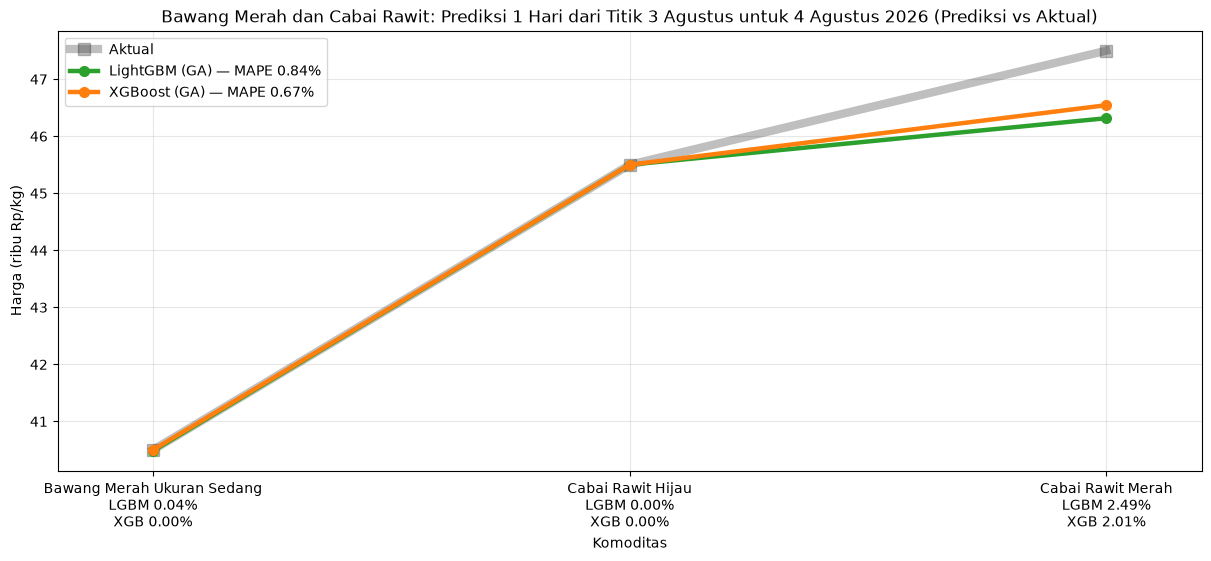

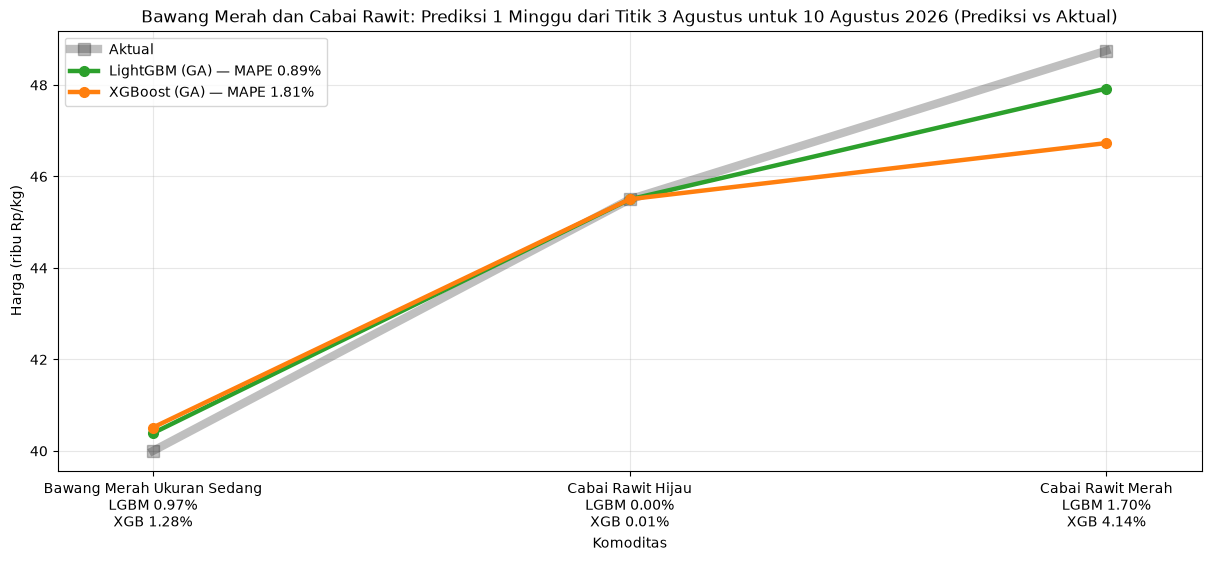

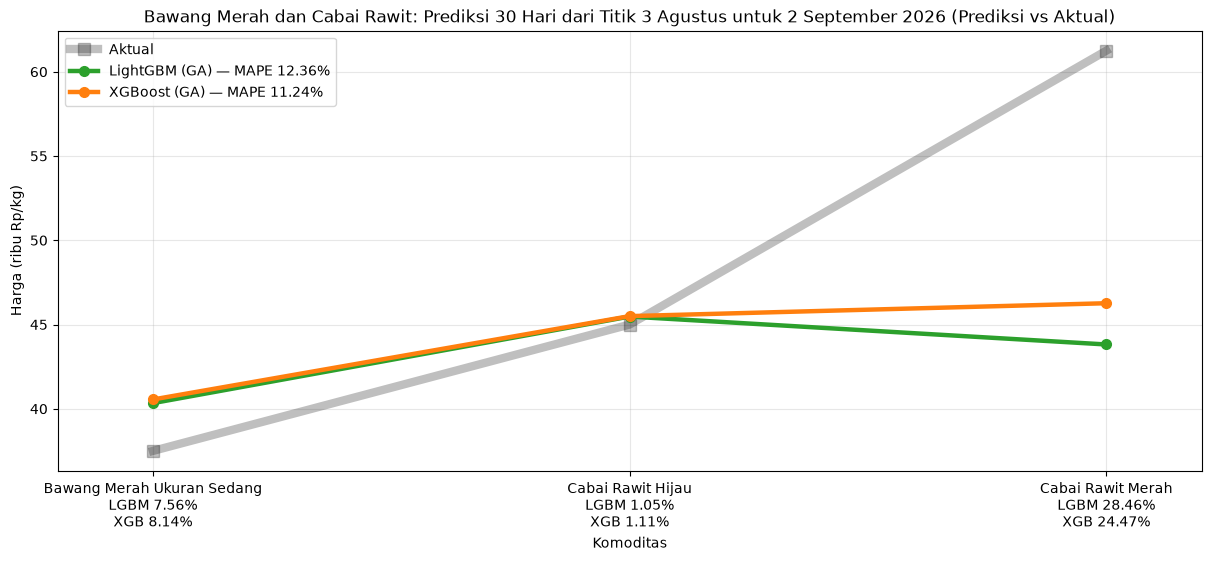

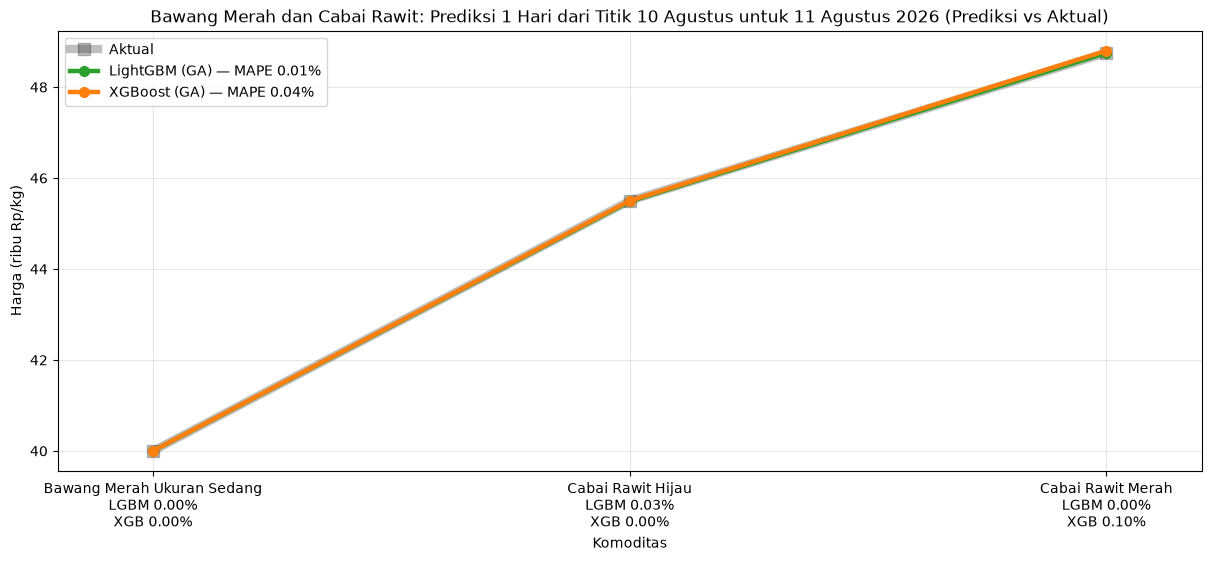

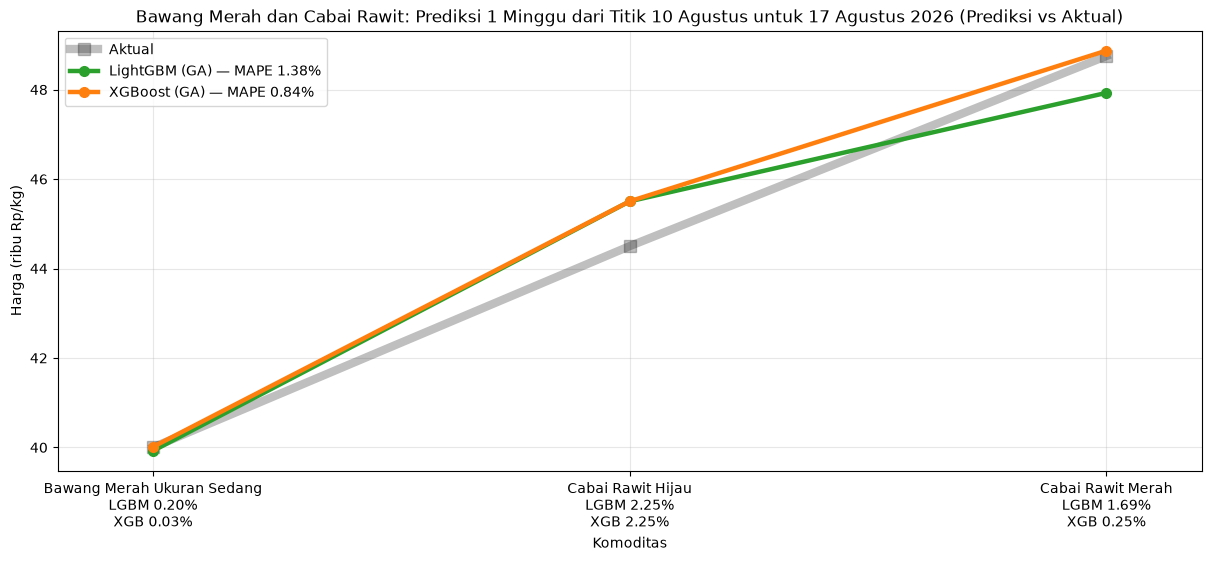

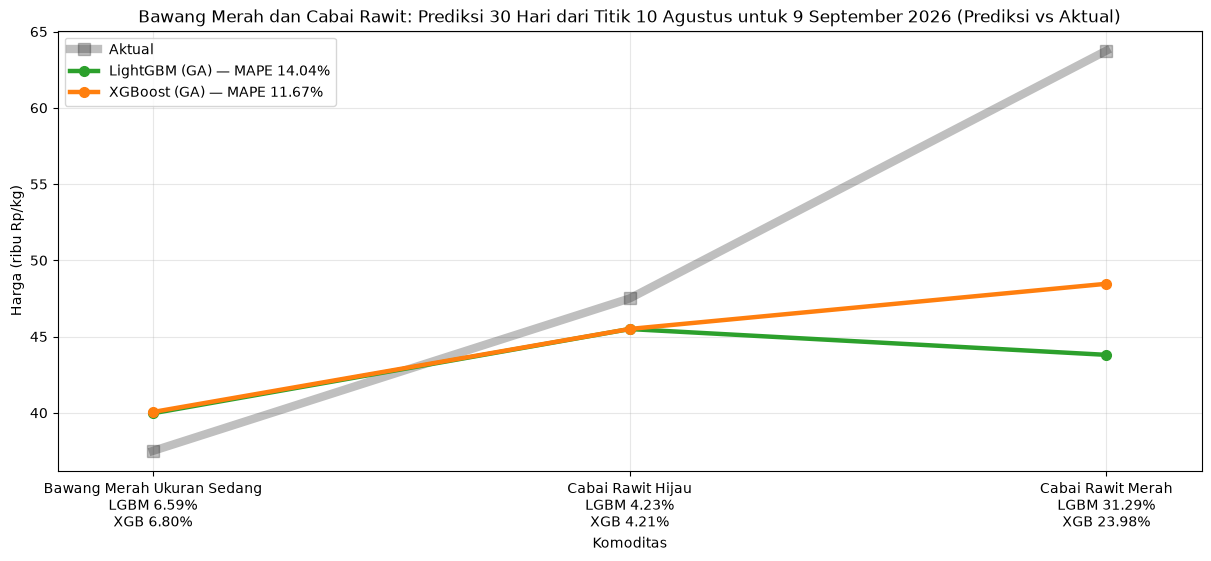

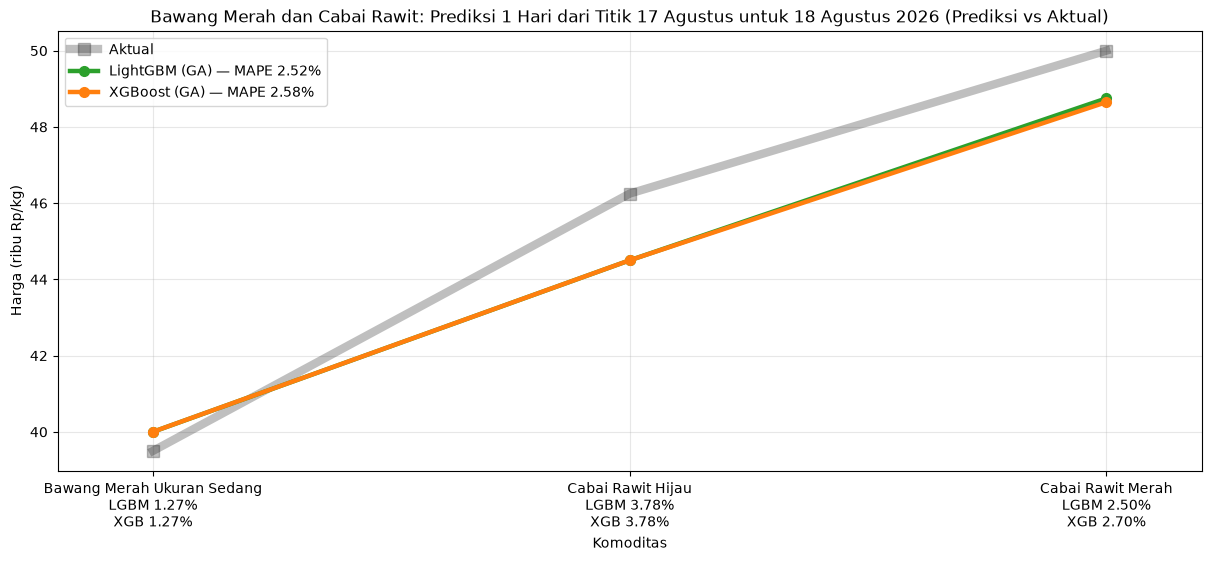

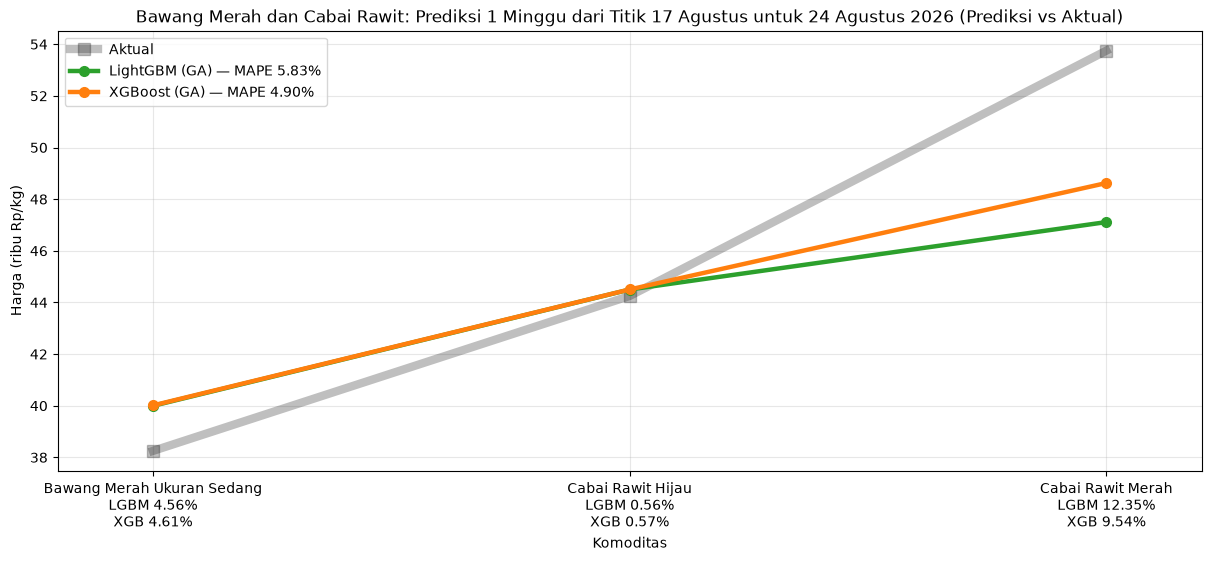

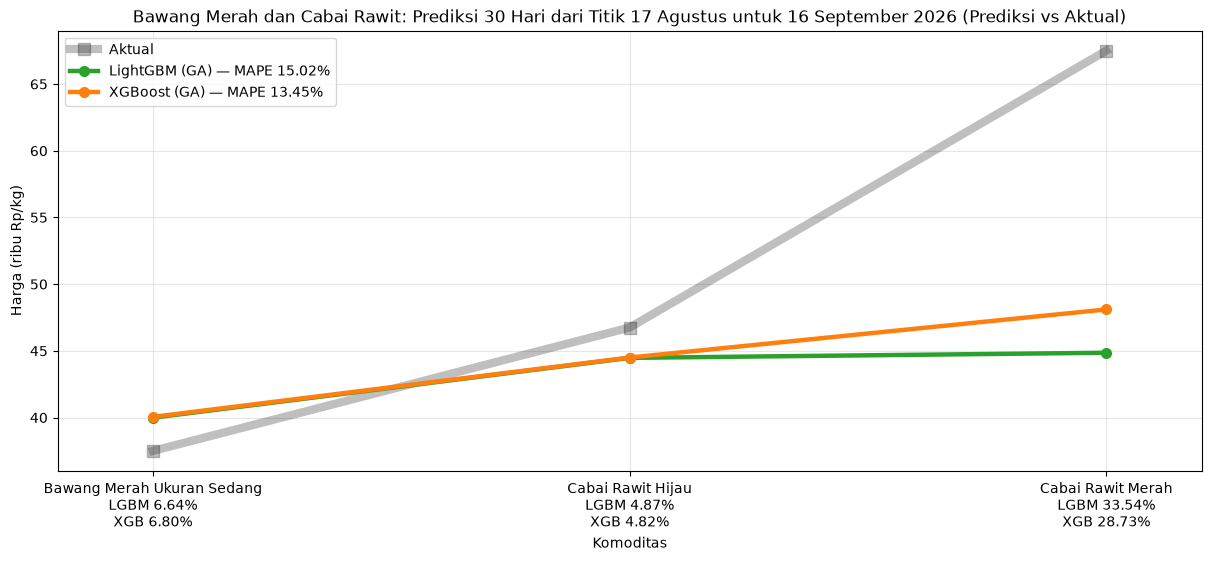

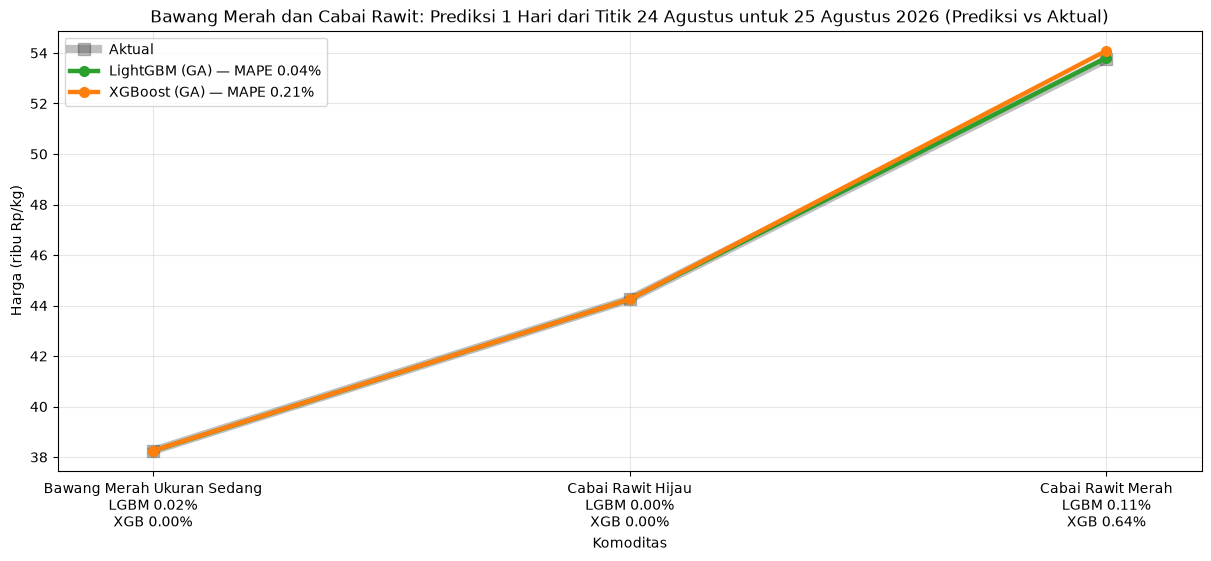

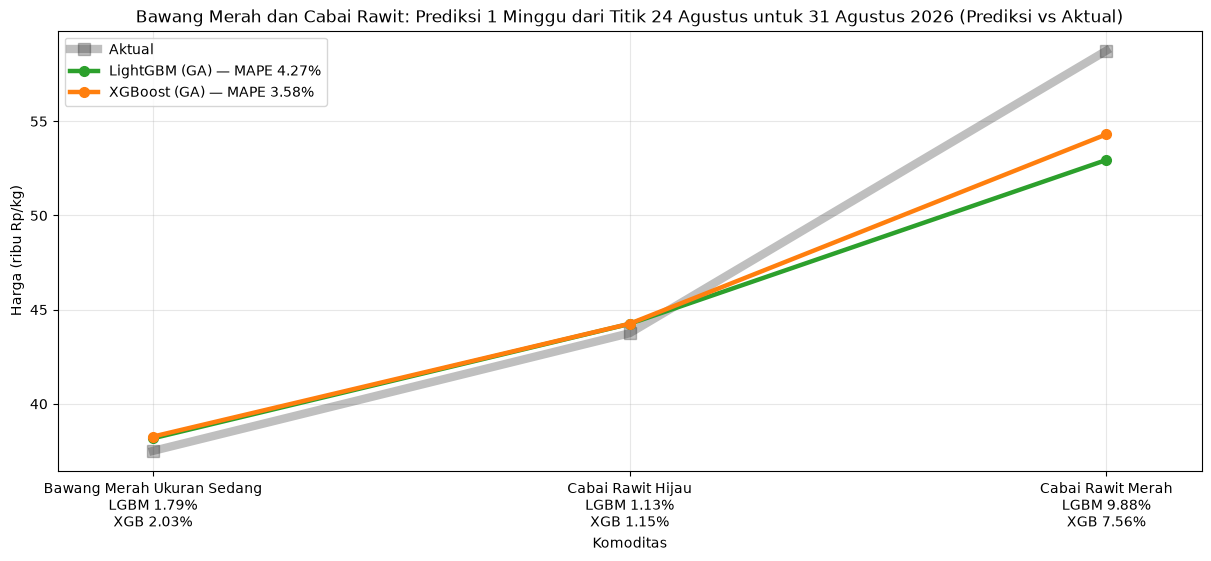

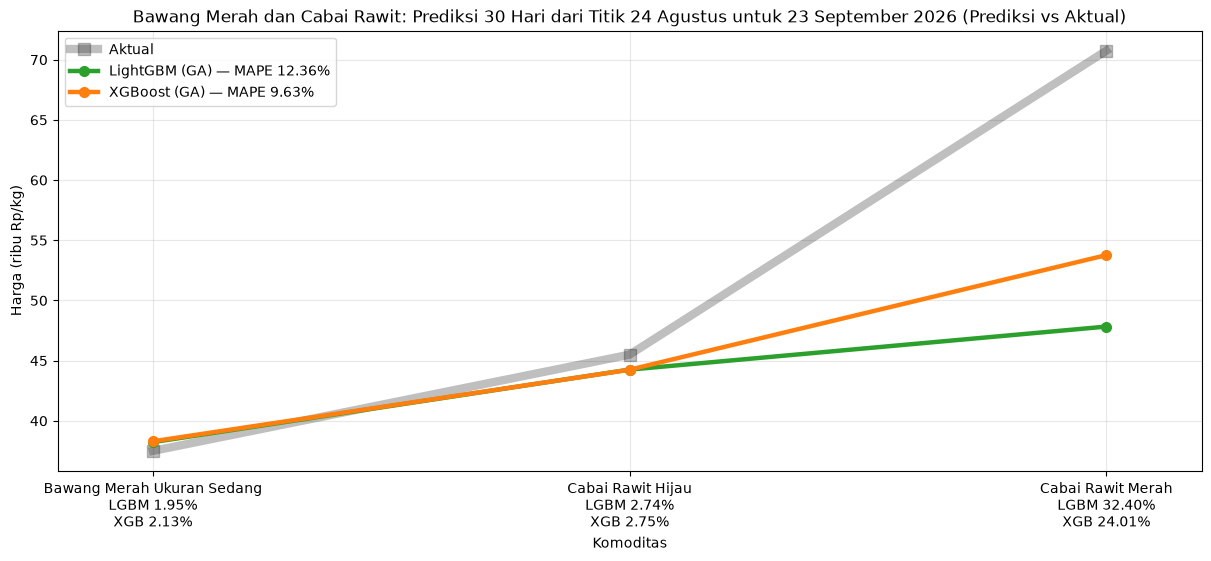

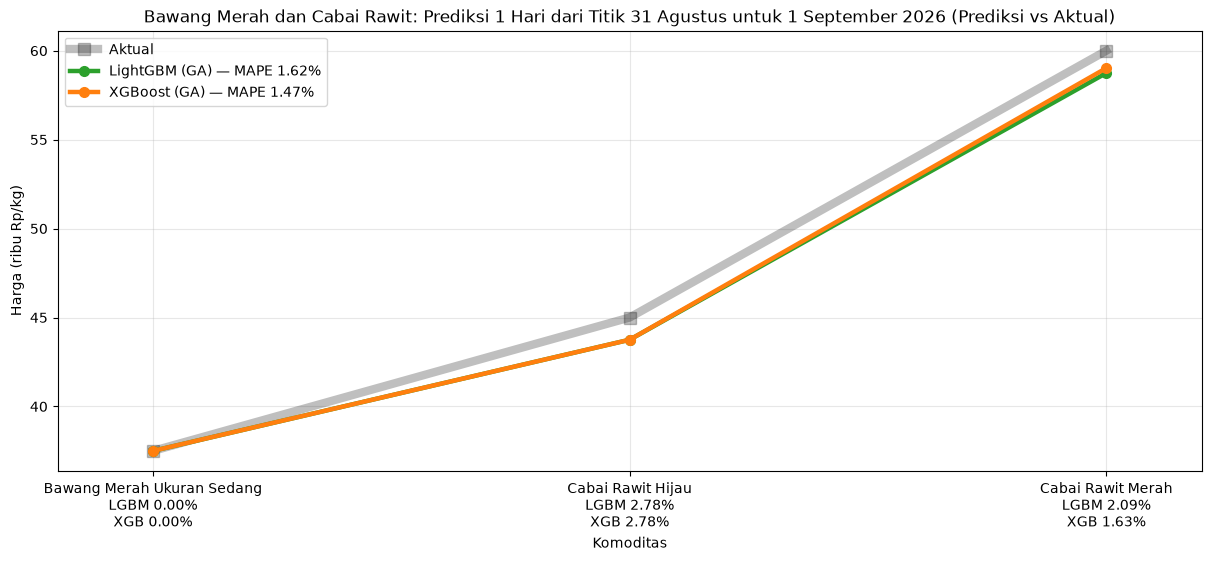

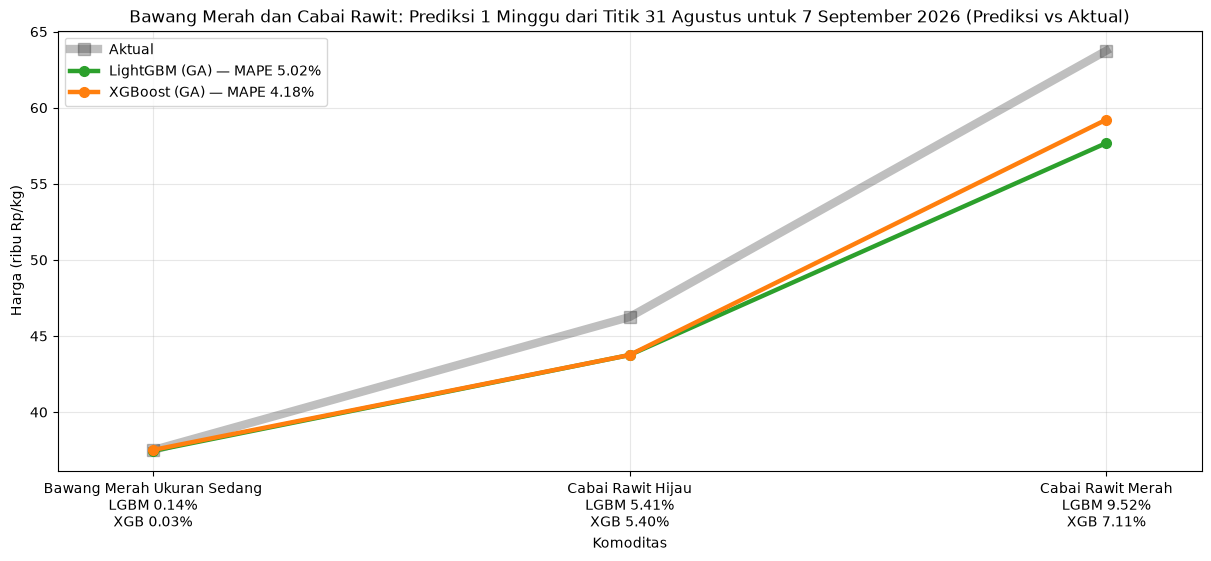

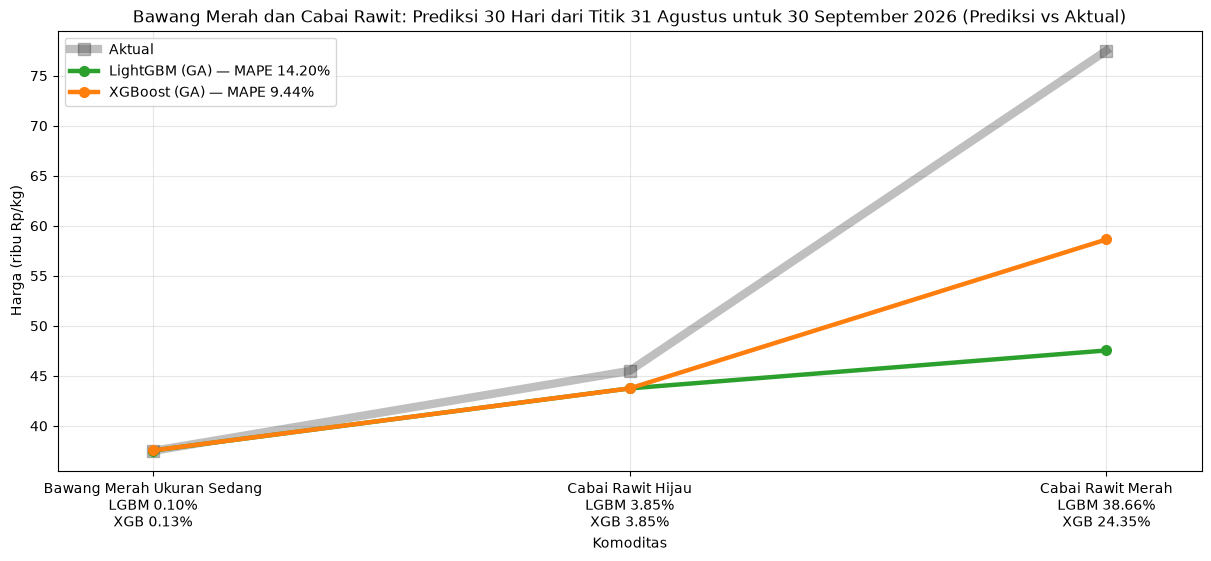

In [15]:
bawang_cabai = [k for k in df_aktual.columns if not k.startswith("Beras")]
for origin in ORIGINS:
    for h in HORIZONS:
        plot_hari_terakhir(
            bawang_cabai, "Bawang Merah dan Cabai Rawit", "Komoditas", origin, h
        )